In [1]:
import sys
sys.path.append("..")
sys.path.append("Guidestar_model")
import time
import itertools
import pandas as pd
import os
import numpy as np
from typing import Union
import random
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
import matplotlib.font_manager as fm
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc, RocCurveDisplay, precision_recall_curve, average_precision_score
from sklearn.utils import resample
from sklearn.pipeline import Pipeline
from Guidestar_model.DiscretisationFunctions import *
from utilsN.FPKM_functions import *

# ---- Main folder = the repository folder, which holds Data/ (layout described in Data/README.md). ----
# Run this from the folder the file is in, or set the environment variable GUIDESTAR_MAIN_DIR to the repository path.
main_dir = os.environ.get('GUIDESTAR_MAIN_DIR', '..')


plt.rcParams['font.family'] = 'Arial'


### LM50 BRAIN

training file used: <main_dir>/Data/20250728_Lm50GS_mbrain_3cT3\output/user_86FOVs_mag0_10_lc350_20250929_1705/final_ver/Tissue_LM50GS_86FOVs_GuidestarGenes_training_set1.csv
test fovs: ['000_006', '000_007', '000_008', '000_009', '001_006', '001_007', '001_008', '001_009', '002_006', '002_007', '002_008', '002_009', '003_006', '003_007', '003_008', '003_009']
resampling fov 009_001
Number of blanks (0)s:  7402
Number of merfishonly (0)s:  993
Number of colocalized genes (1)s:  50
Number of blanks (0)s:  0
Number of merfishonly (0)s:  993
Number of colocalized genes (1)s:  50
resampling fov 003_005
Number of blanks (0)s:  4610
Number of merfishonly (0)s:  636
Number of colocalized genes (1)s:  1079
Number of blanks (0)s:  0
Number of merfishonly (0)s:  636
Number of colocalized genes (1)s:  1079
resampling fov 008_001
Number of blanks (0)s:  6120
Number of merfishonly (0)s:  1138
Number of colocalized genes (1)s:  79
Number of blanks (0)s:  0
Number of merfishonly (0)s:  1138
Number of

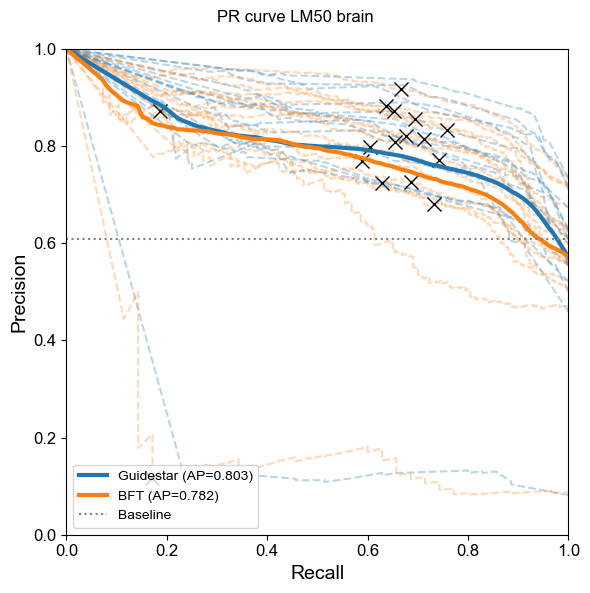

In [4]:
gs_main = os.path.join(main_dir, 'Data/20250728_Lm50GS_mbrain_3cT3')
GS_filepath = os.path.join(gs_main, 'output/user_86FOVs_mag0_10_lc350_20250929_1705/final_ver/Tissue_LM50GS_86FOVs_GuidestarGenes_training_set1.csv')
GS_genes_data = pd.read_csv(GS_filepath).drop(columns=['Unnamed: 0'])

merfish_filepath = os.path.join(gs_main, 'output/user_86FOVs_mag0_10_lc350_20250929_1705/final_ver/Tissue_LM50GS_86FOVs_MerfishData_set1.csv')
merfish_data = pd.read_csv(merfish_filepath).drop(columns=['Unnamed: 0'])

blanks_data = merfish_data.loc[(merfish_data['fov'].isin(GS_genes_data['fov'].unique())) &
                               (merfish_data['gene'].str.startswith('Blank'))]
GS_genes_data = pd.concat([GS_genes_data, blanks_data])

output_dir = os.path.join(gs_main, 'output/user_86FOVs_mag0_10_lc350_20250929_1705/final_ver')
fpkm_path = os.path.join(gs_main, 'codebook/fpkm_data.txt')
df_fpkm = pd.read_csv(fpkm_path, sep=',', header=None, names=['genes','FPKM'])

GS_gene_list = ['Slc1a2', 'Cacna1i', 'Cacna1a']
blank_list = [i for i in GS_genes_data['gene'].unique() if i.startswith('Blank')]
cv_fold = 5
features_to_use = ['meaninten1_frob', 'meaninten1_3_ratio_frob_clipped', 'mindist2_clipped', 'mindist3_clipped', 'size_conn']
blank_ratio = 0
merfish_ratio = None
colocal_ratio = None
bft=0.25

### USER TO FILL IN ###

print('training file used:', GS_filepath)
GS_genes_data = GS_genes_data.loc[GS_genes_data['gene'].isin(GS_gene_list+blank_list)]

type_list = []
for row in range(len(GS_genes_data)):
    if GS_genes_data['Label'].iloc[row] == 0:
        if GS_genes_data['gene'].iloc[row] in blank_list:
            type_list.append('blank')
        elif GS_genes_data['gene'].iloc[row] in GS_gene_list:
            type_list.append('merfishonly')
    elif GS_genes_data['Label'].iloc[row] == 1:
        type_list.append('colocalgene')
        
GS_genes_data['type'] = type_list

# Process features 
GS_genes_data['meaninten1_3_ratio_frob'] = GS_genes_data['meaninten1_frob'] / GS_genes_data['meaninten3_frob']
temp = GS_genes_data['meaninten1_3_ratio_frob'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['meaninten1_3_ratio_frob_clipped'] = np.clip(GS_genes_data['meaninten1_3_ratio_frob'],a_min=np.min(GS_genes_data['meaninten1_3_ratio_frob']),a_max=14)

temp = GS_genes_data['mindist2'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['mindist2_clipped'] = np.clip(GS_genes_data['mindist2'],a_min=np.min(GS_genes_data['mindist2']),a_max=GS_genes_data['mindist2'].iloc[np.nanargmax(temp)])

temp = GS_genes_data['mindist3'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['mindist3_clipped'] = np.clip(GS_genes_data['mindist3'],a_min=np.min(GS_genes_data['mindist3']),a_max=GS_genes_data['mindist3'].iloc[np.nanargmax(temp)])

merfish_data['meaninten1_3_ratio_frob'] = merfish_data['meaninten1_frob'] / merfish_data['meaninten3_frob']
temp = merfish_data['meaninten1_3_ratio_frob'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['meaninten1_3_ratio_frob_clipped'] = np.clip(merfish_data['meaninten1_3_ratio_frob'],a_min=np.min(merfish_data['meaninten1_3_ratio_frob']),a_max=14)

temp = merfish_data['mindist2'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['mindist2_clipped'] = np.clip(merfish_data['mindist2'],a_min=np.min(merfish_data['mindist2']),a_max=merfish_data['mindist2'].iloc[np.nanargmax(temp)])

temp = merfish_data['mindist3'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['mindist3_clipped'] = np.clip(merfish_data['mindist3'],a_min=np.min(merfish_data['mindist3']),a_max=merfish_data['mindist3'].iloc[np.nanargmax(temp)])

# test set
# if we have 86 FOVs, use 16 for testing

# test FOVs determined from selection in optimising number of genes
# testing_fovs = ['004_009', '003_005', '001_002', '009_001', '008_001', '004_005', '009_009',
#  '005_005', '006_004', '002_009', '009_007', '005_001', '005_009', '007_003',
#  '002_005', '008_009', '002_003']

testing_fovs = ['000_006','000_007','000_008','000_009','001_006','001_007','001_008','001_009',
                '002_006','002_007','002_008','002_009','003_006','003_007','003_008','003_009']

X_test = GS_genes_data[features_to_use + ['type', 'Label','fov']].loc[GS_genes_data['fov'].isin(testing_fovs)]
Y_test = GS_genes_data[['Label','gene','bfs','type','fov']].loc[GS_genes_data['fov'].isin(testing_fovs)]
Y_test['bft_result'] = 0
Y_test.loc[Y_test['bfs'] <= bft, 'bft_result'] = 1
GS_training = GS_genes_data.loc[~GS_genes_data['fov'].isin(testing_fovs)]
print('test fovs:', testing_fovs)

random.seed(0)
training_fovs = [i for i in GS_genes_data['fov'].unique() if i not in testing_fovs] # BRAIN

# resample training data
resampled_GS_training = pd.DataFrame()
for train_fov in training_fovs:
    print('resampling fov', train_fov)
    fov_subset = GS_training.loc[GS_training['fov']== train_fov]

    GS_df = fov_subset.loc[fov_subset['type']=='colocalgene']
    merfish_df = fov_subset.loc[fov_subset['type']=='merfishonly']
    blank_df = fov_subset.loc[fov_subset['type']=='blank']

    print('Number of blanks (0)s: ', len(blank_df))
    print('Number of merfishonly (0)s: ', len(merfish_df))
    print('Number of colocalized genes (1)s: ', len(GS_df))

    # can match number of blanks to merfishonly
    # or topup merfishonly to colocalgenes with blanks
    if blank_ratio == 'match':
        colocal_diff = len(GS_df) - len(merfish_df)
        if colocal_diff < 0:
            blank_df_resampled = pd.DataFrame()
        elif colocal_diff > 0:
            blank_df_resampled =  resample(blank_df, replace = True, n_samples = int(abs(colocal_diff)), random_state=0)
        else:
            blank_df_resampled = pd.DataFrame()
    elif blank_ratio is not None and isinstance(blank_ratio, (int, np.integer))==True and len(blank_df) > int(len(merfish_df)*blank_ratio): # match blanks to merfishonly
        blank_df_resampled =  resample(blank_df, replace = False, n_samples = int(len(merfish_df)*blank_ratio), random_state=0)
    else:
        blank_df_resampled = pd.DataFrame()
        
    if merfish_ratio is not None and len(merfish_df) > int(len(GS_df)*merfish_ratio):
        merfish_df_resampled =  resample(merfish_df, replace = False, n_samples = int(len(GS_df)*merfish_ratio), random_state=0)
    elif merfish_ratio is not None and len(merfish_df) < int(len(GS_df)*merfish_ratio):
        merfish_df_resampled =  resample(merfish_df, replace = True, n_samples = int(len(GS_df)*merfish_ratio), random_state=0)
    else:
        merfish_df_resampled = merfish_df
        
    if colocal_ratio is not None and len(GS_df) > int(len(merfish_df_resampled)*colocal_ratio):
        GS_df_resampled =  resample(GS_df, replace = False, n_samples = int(len(merfish_df_resampled)*colocal_ratio), random_state=0)
    elif colocal_ratio is not None and len(GS_df) < int(len(merfish_df_resampled)*colocal_ratio):
        GS_df_resampled =  resample(GS_df, replace = True, n_samples = int(len(merfish_df_resampled)*colocal_ratio), random_state=0)
    else:
        GS_df_resampled = GS_df
        
    print('Number of blanks (0)s: ', len(blank_df_resampled))
    print('Number of merfishonly (0)s: ', len(merfish_df_resampled))
    print('Number of colocalized genes (1)s: ', len(GS_df_resampled))
    
    resampled_fov = pd.concat([GS_df_resampled, blank_df_resampled, merfish_df_resampled])
    resampled_GS_training = pd.concat([resampled_GS_training,resampled_fov])
    
resampled_GS_training = resampled_GS_training.reset_index()

# define model
print('features used:', features_to_use)
RF = RandomForestClassifier(random_state=0, verbose=0, n_jobs=-3, min_samples_split=0.001,
                            min_impurity_decrease=0.01, max_features=1, max_depth=12,
                            criterion='entropy', min_weight_fraction_leaf=0.175,
                            n_estimators=300, max_samples=None)
print('random forest model:', RF)

cm = ChiMergeTransformer(attr_list=features_to_use,min_intervals=2,hot_start_num_intervals=1000,allow_early_stop=True)

pipe = Pipeline([
    ('discretizer', cm),
    ('remove_labels', columnDropperTransformer(columns=['Label'])),
    ('model', RF)
])

pipe.fit(resampled_GS_training[features_to_use+['Label']], resampled_GS_training['Label'])

# PR curve
precisions_model = []
recalls_model = []
aps_model = []
precisions_bft = []
recalls_bft = []
aps_bft = []
mean_recall = np.linspace(0, 1, 100)

fig1, ax1 = plt.subplots(1, 1, figsize=(6, 6))

for j, test_fov in enumerate(X_test['fov'].unique()):

    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])

    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(fov_subset_transformed[col].max())

    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov].copy()
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
    Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]

    mask = Y_fov_subset['gene'].isin(GS_gene_list)

    y_true = Y_fov_subset.loc[mask, 'Label']
    y_score_model = Y_fov_subset.loc[mask, 'pred_score']
    y_score_bft = 1 - Y_fov_subset.loc[mask, 'bfs']

    # ---- MODEL PR CURVE ----
    precision_model, recall_model, _ = precision_recall_curve(y_true, y_score_model)
    ap_model = average_precision_score(y_true, y_score_model)
    interp_precision_model = np.interp(mean_recall, recall_model[::-1], precision_model[::-1])
    precisions_model.append(interp_precision_model)
    aps_model.append(ap_model)

    # ---- BFT PR CURVE ----
    precision_bft, recall_bft, _ = precision_recall_curve(y_true, y_score_bft)
    ap_bft = average_precision_score(y_true, y_score_bft)
    interp_precision_bft = np.interp(mean_recall, recall_bft[::-1], precision_bft[::-1])
    precisions_bft.append(interp_precision_bft)
    aps_bft.append(ap_bft)

    # Plot individual FOV curves
    ax1.plot(recall_model, precision_model, linestyle='dashed', alpha=0.3, color='tab:blue', linewidth=1.5)
    ax1.plot(recall_bft, precision_bft, linestyle='dashed', alpha=0.3, color='tab:orange', linewidth=1.5)

    # ---- Plot BFT operating point ----
    TP = len(Y_fov_subset.loc[(Y_fov_subset['Label'] == 1) &
                              (Y_fov_subset['bft_result'] == 1) & mask])
    FP = len(Y_fov_subset.loc[(Y_fov_subset['Label'] == 0) &
                              (Y_fov_subset['bft_result'] == 1) & mask])
    FN = len(Y_fov_subset.loc[(Y_fov_subset['Label'] == 1) &
                              (Y_fov_subset['bft_result'] == 0) & mask])

    recall_point = TP / (TP + FN) if (TP + FN) > 0 else 0
    precision_point = TP / (TP + FP) if (TP + FP) > 0 else 0

    ax1.plot(recall_point, precision_point, 'x', color='black', markersize=10)

# ---- Mean PR curves ----
mean_precision_model = np.mean(precisions_model, axis=0)
mean_precision_bft = np.mean(precisions_bft, axis=0)
ap_mean_model = np.sum(np.diff(mean_recall) * mean_precision_model[1:])
ap_mean_bft = np.sum(np.diff(mean_recall) * mean_precision_bft[1:])

ax1.plot(mean_recall, mean_precision_model, color='tab:blue', linewidth=3, label=f'Guidestar (AP={ap_mean_model:.3f})')
ax1.plot(mean_recall, mean_precision_bft, color='tab:orange', linewidth=3, label=f'BFT (AP={ap_mean_bft:.3f})')

# ---- Baseline (class prevalence) ----
prevalence = y_true.mean()
ax1.hlines(prevalence, 0, 1, linestyles='dotted', colors='gray',
           label='Baseline')

ax1.set_xlabel('Recall', fontsize=14)
ax1.set_ylabel('Precision', fontsize=14)
ax1.set_xlim([0, 1])
ax1.set_ylim([0, 1])
ax1.tick_params(axis='both', labelsize=12)
ax1.legend(loc='lower left')
fig1.suptitle('PR curve LM50 brain')
fig1.tight_layout()
fig1.savefig(os.path.join(output_dir, 'PR_curve_LM50brain.svg'))


### LM39 CELL

training file used: <main_dir>/Data/100uM/output/colocalisation/colocaldist4_20240610/Cell_LM39_25FOVs_GuidestarGenes_training.csv
train fovs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
test fovs: [20, 21, 22, 23, 24]
resampling fov 0
Number of blanks (0)s:  1596
Number of merfishonly (0)s:  411
Number of colocalized genes (1)s:  1518
Number of blanks (0)s:  411
Number of merfishonly (0)s:  411
Number of colocalized genes (1)s:  1518
resampling fov 1
Number of blanks (0)s:  2144
Number of merfishonly (0)s:  814
Number of colocalized genes (1)s:  3280
Number of blanks (0)s:  814
Number of merfishonly (0)s:  814
Number of colocalized genes (1)s:  3280
resampling fov 2
Number of blanks (0)s:  2164
Number of merfishonly (0)s:  802
Number of colocalized genes (1)s:  3062
Number of blanks (0)s:  802
Number of merfishonly (0)s:  802
Number of colocalized genes (1)s:  3062
resampling fov 3
Number of blanks (0)s:  2204
Number of merfishonly (0)s:  1040
Number of colo

<repo>/Guidestar_model/DiscretisationFunctions.py:69: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts_arr = data.groupby(['bin',label]).count().iloc[:,0].to_numpy().reshape((len(intervals),len(np.unique(data[label]))))
<repo>/Guidestar_model/DiscretisationFunctions.py:69: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts_arr = data.groupby(['bin',label]).count().iloc[:,0].to_numpy().reshape((len(intervals),len(np.unique(data[label]))))
<repo>/Guidestar_model/DiscretisationFunctions.py:69: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pand

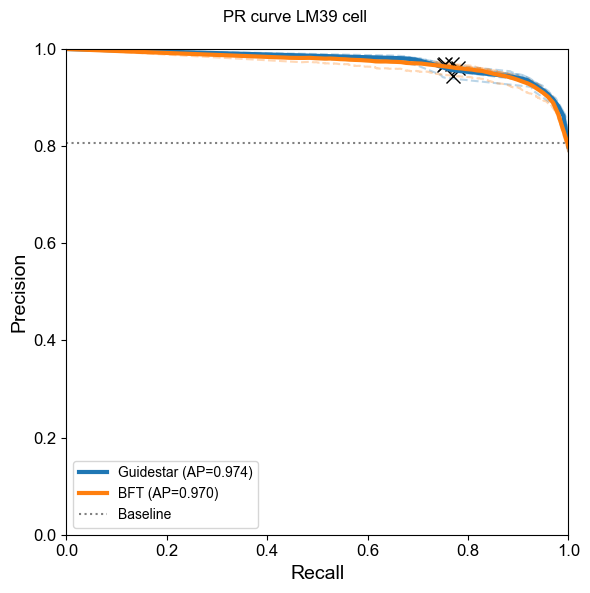

In [3]:

GS_filepath = os.path.join(main_dir, 'Data/100uM/output/colocalisation/colocaldist4_20240610/Cell_LM39_25FOVs_GuidestarGenes_training.csv')
merfish_filepath = os.path.join(main_dir, 'Data/100uM/output/colocalisation/colocaldist4_20240610/Cell_LM39_25FOVs_MerfishData.csv')
fpkm_path = '../DataForFigures/cell_fpkm_data.tsv'
df_fpkm = pd.read_csv(fpkm_path, sep='\t', header=None, names=['genes','FPKM'])

GS_genes_data = pd.read_csv(GS_filepath)
merfish_data = pd.read_csv(merfish_filepath)
output_dir = os.path.join(main_dir, 'Data/model_optimisation/20260131')


# CELL
GS_gene_list = ['Acly','Hnf4a','Ube2z','Gpam']
blank_no = 7
blank_list = ['Blank' + str(i) for i in range(1,blank_no+1)]
cv_fold = 5
features_to_use = ['meaninten1_frob', 'mindist2_clipped', 'mindist3_clipped', 'size']
blank_ratio = 1
merfish_ratio = None
colocal_ratio = None
bft = 0.29
nfovs = 25

print('training file used:', GS_filepath)
GS_genes_data = GS_genes_data.loc[GS_genes_data['gene'].isin(GS_gene_list+blank_list)]

type_list = []
for row in range(len(GS_genes_data)):
    if GS_genes_data['Label'].iloc[row] == 0:
        if GS_genes_data['gene'].iloc[row] in blank_list:
            type_list.append('blank')
        elif GS_genes_data['gene'].iloc[row] in GS_gene_list:
            type_list.append('merfishonly')
    elif GS_genes_data['Label'].iloc[row] == 1:
        type_list.append('colocalgene')
        
GS_genes_data['type'] = type_list

# Process features 
temp = GS_genes_data['mindist2'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['mindist2_clipped'] = np.clip(GS_genes_data['mindist2'],a_min=np.min(GS_genes_data['mindist2']),a_max=GS_genes_data['mindist2'].iloc[np.nanargmax(temp)])

temp = GS_genes_data['mindist3'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['mindist3_clipped'] = np.clip(GS_genes_data['mindist3'],a_min=np.min(GS_genes_data['mindist3']),a_max=GS_genes_data['mindist3'].iloc[np.nanargmax(temp)])

temp = merfish_data['mindist2'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['mindist2_clipped'] = np.clip(merfish_data['mindist2'],a_min=np.min(merfish_data['mindist2']),a_max=merfish_data['mindist2'].iloc[np.nanargmax(temp)])

temp = merfish_data['mindist3'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['mindist3_clipped'] = np.clip(merfish_data['mindist3'],a_min=np.min(merfish_data['mindist3']),a_max=merfish_data['mindist3'].iloc[np.nanargmax(temp)])

# test set
testing_fovs = [i for i in range(20,25)]
training_fovs = [i for i in range(20)]
X_test = GS_genes_data[features_to_use + ['type', 'Label', 'fov']].loc[GS_genes_data['fov'].isin(testing_fovs)]
Y_test = GS_genes_data[['Label','gene','bfs','type','fov']].loc[GS_genes_data['fov'].isin(testing_fovs)]
Y_test['bft_result'] = 0
Y_test.loc[Y_test['bfs'] <= bft, 'bft_result'] = 1
GS_training = GS_genes_data.loc[GS_genes_data['fov'].isin(training_fovs)]
print('train fovs:', training_fovs)
print('test fovs:', testing_fovs)

# resample training data
resampled_GS_training = pd.DataFrame()
for train_fov in training_fovs:
    print('resampling fov', train_fov)
    fov_subset = GS_training.loc[GS_training['fov']== train_fov]

    GS_df = fov_subset.loc[fov_subset['type']=='colocalgene']
    merfish_df = fov_subset.loc[fov_subset['type']=='merfishonly']
    blank_df = fov_subset.loc[fov_subset['type']=='blank']

    print('Number of blanks (0)s: ', len(blank_df))
    print('Number of merfishonly (0)s: ', len(merfish_df))
    print('Number of colocalized genes (1)s: ', len(GS_df))

    # can match number of blanks to merfishonly
    # or topup merfishonly to colocalgenes with blanks
    if blank_ratio == 'match':
        colocal_diff = len(GS_df) - len(merfish_df)
        if colocal_diff < 0:
            blank_df_resampled = pd.DataFrame()
        elif colocal_diff > 0:
            blank_df_resampled =  resample(blank_df, replace = True, n_samples = int(abs(colocal_diff)), random_state=0)
        else:
            blank_df_resampled = pd.DataFrame()
    elif blank_ratio is not None and isinstance(blank_ratio, (int, np.integer))==True and len(blank_df) > int(len(merfish_df)*blank_ratio): # match blanks to merfishonly
        blank_df_resampled =  resample(blank_df, replace = False, n_samples = int(len(merfish_df)*blank_ratio), random_state=0)
    else:
        blank_df_resampled = pd.DataFrame()
        
    if merfish_ratio is not None and len(merfish_df) > int(len(GS_df)*merfish_ratio):
        merfish_df_resampled =  resample(merfish_df, replace = False, n_samples = int(len(GS_df)*merfish_ratio), random_state=0)
    elif merfish_ratio is not None and len(merfish_df) < int(len(GS_df)*merfish_ratio):
        merfish_df_resampled =  resample(merfish_df, replace = True, n_samples = int(len(GS_df)*merfish_ratio), random_state=0)
    else:
        merfish_df_resampled = merfish_df
        
    if colocal_ratio is not None and len(GS_df) > int(len(merfish_df_resampled)*colocal_ratio):
        GS_df_resampled =  resample(GS_df, replace = False, n_samples = int(len(merfish_df_resampled)*colocal_ratio), random_state=0)
    elif colocal_ratio is not None and len(GS_df) < int(len(merfish_df_resampled)*colocal_ratio):
        GS_df_resampled =  resample(GS_df, replace = True, n_samples = int(len(merfish_df_resampled)*colocal_ratio), random_state=0)
    else:
        GS_df_resampled = GS_df
        
    print('Number of blanks (0)s: ', len(blank_df_resampled))
    print('Number of merfishonly (0)s: ', len(merfish_df_resampled))
    print('Number of colocalized genes (1)s: ', len(GS_df))
    
    resampled_fov = pd.concat([GS_df, blank_df_resampled, merfish_df_resampled])
    resampled_GS_training = pd.concat([resampled_GS_training,resampled_fov])
    
resampled_GS_training = resampled_GS_training.reset_index()

# define model
print('features used:', features_to_use)
RF = RandomForestClassifier(random_state=0, verbose=0,n_jobs=-3, min_samples_split=0.001, min_impurity_decrease=0.01, max_features=1,
                                max_depth=12,criterion='gini',min_weight_fraction_leaf=0.01,n_estimators=100, max_samples= 0.8)
print('random forest model:', RF)

cm = ChiMergeTransformer(attr_list=features_to_use,min_intervals=2,hot_start_num_intervals=1000,allow_early_stop=True)

pipe = Pipeline([
    ('discretizer', cm),
    ('remove_labels', columnDropperTransformer(columns=['Label'])),
    ('model', RF)
])

pipe.fit(resampled_GS_training[features_to_use+['Label']], resampled_GS_training['Label'])

model_precision = []
model_recall = []
model_f1 = []
model_auroc = []
bft_precision = []
bft_recall = []
bft_f1 = []
bft_auroc = []
for test_fov in testing_fovs:
    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])
    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(fov_subset_transformed[col].max())
    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov]
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
    Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]
    
    model_precision.append(precision_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                           Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_recall.append(recall_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                     Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_f1.append(f1_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                             Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_auroc.append(roc_auc_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                     Y_fov_subset['pred_score'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    
    bft_precision.append(precision_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                         Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_recall.append(recall_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                   Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_f1.append(f1_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                           Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_auroc.append(roc_auc_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                   1 - Y_fov_subset['bfs'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    
results_df = pd.DataFrame({'fov': testing_fovs, 'model_precision': model_precision, 'model_recall': model_recall,
                           'model_f1': model_f1, 'model_auroc': model_auroc,
                           'bft_precision': bft_precision, 'bft_recall': bft_recall,
                           'bft_f1': bft_f1, 'bft_auroc': bft_auroc})
results_df.to_csv(os.path.join(output_dir,'testset_results_cell.csv'))

# PR curve
precisions_model = []
recalls_model = []
aps_model = []
precisions_bft = []
recalls_bft = []
aps_bft = []
mean_recall = np.linspace(0, 1, 100)

fig1, ax1 = plt.subplots(1, 1, figsize=(6, 6))

for j, test_fov in enumerate(X_test['fov'].unique()):

    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])

    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(fov_subset_transformed[col].max())

    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov].copy()
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
    Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]

    mask = Y_fov_subset['gene'].isin(GS_gene_list)

    y_true = Y_fov_subset.loc[mask, 'Label']
    y_score_model = Y_fov_subset.loc[mask, 'pred_score']
    y_score_bft = 1 - Y_fov_subset.loc[mask, 'bfs']

    # ---- MODEL PR CURVE ----
    precision_model, recall_model, _ = precision_recall_curve(y_true, y_score_model)
    ap_model = average_precision_score(y_true, y_score_model)
    interp_precision_model = np.interp(mean_recall, recall_model[::-1], precision_model[::-1])
    precisions_model.append(interp_precision_model)
    aps_model.append(ap_model)

    # ---- BFT PR CURVE ----
    precision_bft, recall_bft, _ = precision_recall_curve(y_true, y_score_bft)
    ap_bft = average_precision_score(y_true, y_score_bft)
    interp_precision_bft = np.interp(mean_recall, recall_bft[::-1], precision_bft[::-1])
    precisions_bft.append(interp_precision_bft)
    aps_bft.append(ap_bft)

    # Plot individual FOV curves
    ax1.plot(recall_model, precision_model, linestyle='dashed', alpha=0.3, color='tab:blue', linewidth=1.5)
    ax1.plot(recall_bft, precision_bft, linestyle='dashed', alpha=0.3, color='tab:orange', linewidth=1.5)

    # ---- Plot BFT operating point ----
    TP = len(Y_fov_subset.loc[(Y_fov_subset['Label'] == 1) &
                              (Y_fov_subset['bft_result'] == 1) & mask])
    FP = len(Y_fov_subset.loc[(Y_fov_subset['Label'] == 0) &
                              (Y_fov_subset['bft_result'] == 1) & mask])
    FN = len(Y_fov_subset.loc[(Y_fov_subset['Label'] == 1) &
                              (Y_fov_subset['bft_result'] == 0) & mask])

    recall_point = TP / (TP + FN) if (TP + FN) > 0 else 0
    precision_point = TP / (TP + FP) if (TP + FP) > 0 else 0

    ax1.plot(recall_point, precision_point, 'x', color='black', markersize=10)

# ---- Mean PR curves ----
mean_precision_model = np.mean(precisions_model, axis=0)
mean_precision_bft = np.mean(precisions_bft, axis=0)
ap_mean_model = np.sum(np.diff(mean_recall) * mean_precision_model[1:])
ap_mean_bft = np.sum(np.diff(mean_recall) * mean_precision_bft[1:])

ax1.plot(mean_recall, mean_precision_model, color='tab:blue', linewidth=3, label=f'Guidestar (AP={ap_mean_model:.3f})')
ax1.plot(mean_recall, mean_precision_bft, color='tab:orange', linewidth=3, label=f'BFT (AP={ap_mean_bft:.3f})')

# ---- Baseline (class prevalence) ----
prevalence = y_true.mean()
ax1.hlines(prevalence, 0, 1, linestyles='dotted', colors='gray',
           label='Baseline')

ax1.set_xlabel('Recall', fontsize=14)
ax1.set_ylabel('Precision', fontsize=14)
ax1.set_xlim([0, 1])
ax1.set_ylim([0, 1])
ax1.tick_params(axis='both', labelsize=12)
ax1.legend(loc='lower left')
fig1.suptitle('PR curve LM39 cell')
fig1.tight_layout()
# The cell and liver PR curves were saved manually, one at a time: uncomment the savefig line you need.
# fig1.savefig(os.path.join(output_dir, 'PR_curve_LM39cell.svg'))


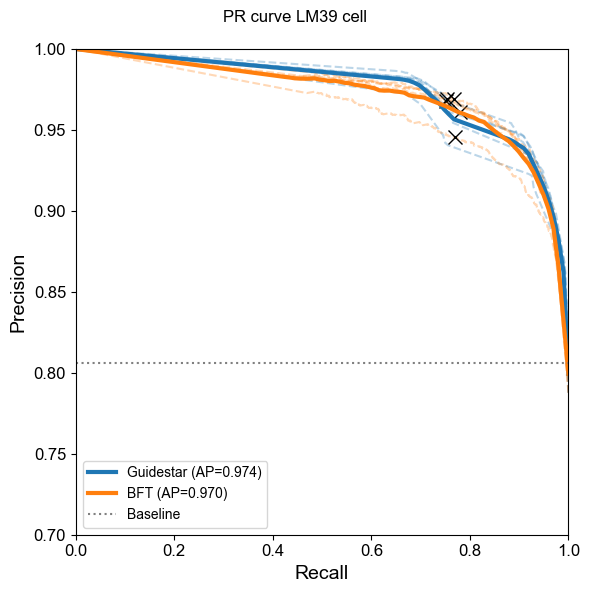

In [4]:

# PR curve
precisions_model = []
recalls_model = []
aps_model = []
precisions_bft = []
recalls_bft = []
aps_bft = []
mean_recall = np.linspace(0, 1, 100)

fig1, ax1 = plt.subplots(1, 1, figsize=(6, 6))

for j, test_fov in enumerate(X_test['fov'].unique()):

    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])

    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(fov_subset_transformed[col].max())

    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov].copy()
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
    Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]

    mask = Y_fov_subset['gene'].isin(GS_gene_list)

    y_true = Y_fov_subset.loc[mask, 'Label']
    y_score_model = Y_fov_subset.loc[mask, 'pred_score']
    y_score_bft = 1 - Y_fov_subset.loc[mask, 'bfs']

    # ---- MODEL PR CURVE ----
    precision_model, recall_model, _ = precision_recall_curve(y_true, y_score_model)
    ap_model = average_precision_score(y_true, y_score_model)
    interp_precision_model = np.interp(mean_recall, recall_model[::-1], precision_model[::-1])
    precisions_model.append(interp_precision_model)
    aps_model.append(ap_model)

    # ---- BFT PR CURVE ----
    precision_bft, recall_bft, _ = precision_recall_curve(y_true, y_score_bft)
    ap_bft = average_precision_score(y_true, y_score_bft)
    interp_precision_bft = np.interp(mean_recall, recall_bft[::-1], precision_bft[::-1])
    precisions_bft.append(interp_precision_bft)
    aps_bft.append(ap_bft)

    # Plot individual FOV curves
    ax1.plot(recall_model, precision_model, linestyle='dashed', alpha=0.3, color='tab:blue', linewidth=1.5)
    ax1.plot(recall_bft, precision_bft, linestyle='dashed', alpha=0.3, color='tab:orange', linewidth=1.5)

    # ---- Plot BFT operating point ----
    TP = len(Y_fov_subset.loc[(Y_fov_subset['Label'] == 1) &
                              (Y_fov_subset['bft_result'] == 1) & mask])
    FP = len(Y_fov_subset.loc[(Y_fov_subset['Label'] == 0) &
                              (Y_fov_subset['bft_result'] == 1) & mask])
    FN = len(Y_fov_subset.loc[(Y_fov_subset['Label'] == 1) &
                              (Y_fov_subset['bft_result'] == 0) & mask])

    recall_point = TP / (TP + FN) if (TP + FN) > 0 else 0
    precision_point = TP / (TP + FP) if (TP + FP) > 0 else 0

    ax1.plot(recall_point, precision_point, 'x', color='black', markersize=10)

# ---- Mean PR curves ----
mean_precision_model = np.mean(precisions_model, axis=0)
mean_precision_bft = np.mean(precisions_bft, axis=0)
ap_mean_model = np.sum(np.diff(mean_recall) * mean_precision_model[1:])
ap_mean_bft = np.sum(np.diff(mean_recall) * mean_precision_bft[1:])

ax1.plot(mean_recall, mean_precision_model, color='tab:blue', linewidth=3, label=f'Guidestar (AP={ap_mean_model:.3f})')
ax1.plot(mean_recall, mean_precision_bft, color='tab:orange', linewidth=3, label=f'BFT (AP={ap_mean_bft:.3f})')

# ---- Baseline (class prevalence) ----
prevalence = y_true.mean()
ax1.hlines(prevalence, 0, 1, linestyles='dotted', colors='gray',
           label='Baseline')

ax1.set_xlabel('Recall', fontsize=14)
ax1.set_ylabel('Precision', fontsize=14)
ax1.set_xlim([0, 1])
ax1.set_ylim([0.7, 1])
ax1.tick_params(axis='both', labelsize=12)
ax1.legend(loc='lower left')
fig1.suptitle('PR curve LM39 cell')
fig1.tight_layout()
# The cell and liver PR curves were saved manually, one at a time: uncomment the savefig line you need.
# fig1.savefig(os.path.join(output_dir, 'PR_curve_LM39cell_zoomed.svg'))


### LM39 LIVER

training file used: <main_dir>/Data/60uM/output/colocalisation/colocaldist4_20240723_try2/Liver_LM39_49FOVs_GuidestarGenes_training.csv
train fovs: [9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48]
test fovs: [0, 1, 2, 3, 4, 5, 6, 7, 8]
resampling fov 9
Number of blanks (0)s:  1324
Number of merfishonly (0)s:  1280
Number of colocalized genes (1)s:  743
Number of blanks (0)s:  0
Number of merfishonly (0)s:  743
Number of colocalized genes (1)s:  743
resampling fov 10
Number of blanks (0)s:  1433
Number of merfishonly (0)s:  1596
Number of colocalized genes (1)s:  683
Number of blanks (0)s:  0
Number of merfishonly (0)s:  683
Number of colocalized genes (1)s:  683
resampling fov 11
Number of blanks (0)s:  1540
Number of merfishonly (0)s:  1400
Number of colocalized genes (1)s:  1262
Number of blanks (0)s:  0
Number of merfishonly (0)s:  1262
Number of colocalized genes (1)s:  12

<repo>/Guidestar_model/DiscretisationFunctions.py:69: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts_arr = data.groupby(['bin',label]).count().iloc[:,0].to_numpy().reshape((len(intervals),len(np.unique(data[label]))))
<repo>/Guidestar_model/DiscretisationFunctions.py:69: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts_arr = data.groupby(['bin',label]).count().iloc[:,0].to_numpy().reshape((len(intervals),len(np.unique(data[label]))))
<repo>/Guidestar_model/DiscretisationFunctions.py:69: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pand

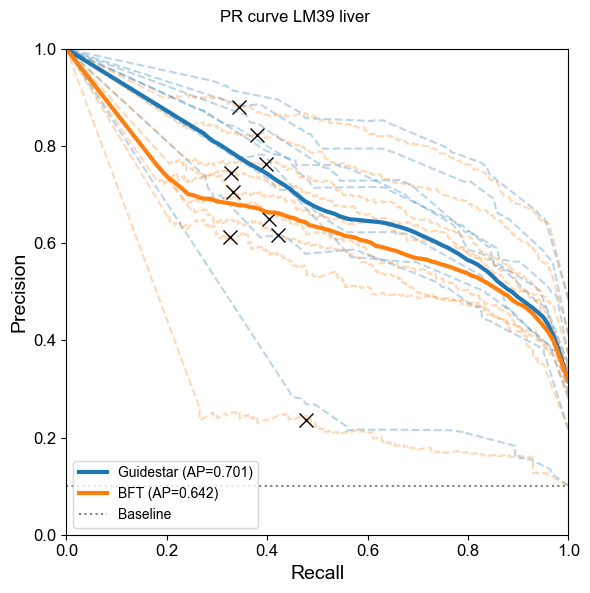

In [5]:

GS_filepath = os.path.join(main_dir, 'Data/60uM/output/colocalisation/colocaldist4_20240723_try2/Liver_LM39_49FOVs_GuidestarGenes_training.csv')
merfish_filepath = os.path.join(main_dir, 'Data/60uM/output/colocalisation/colocaldist4_20240723_try2/Liver_LM39_49FOVs_MerfishData.csv')
fpkm_path = '../DataForFigures/liver_fpkm_data.tsv'
df_fpkm = pd.read_csv(fpkm_path, sep='\t', header=None, names=['genes','FPKM'])

GS_genes_data = pd.read_csv(GS_filepath)
merfish_data = pd.read_csv(merfish_filepath)
output_dir = os.path.join(main_dir, 'Data/model_optimisation/20260131')

# LIVER
GS_gene_list = ['Acly','Hnf4a','Pigr','Gpam']
blank_no = 7
blank_list = ['Blank' + str(i) for i in range(1,blank_no+1)]
cv_fold = 5
features_to_use = ['meaninten1_frob', 'mindist2_clipped', 'mindist3_clipped', 'size']
blank_ratio = None
merfish_ratio = 1
bft = 0.21
nfovs = 49

print('training file used:', GS_filepath)
GS_genes_data = GS_genes_data.loc[GS_genes_data['gene'].isin(GS_gene_list+blank_list)]

type_list = []
for row in range(len(GS_genes_data)):
    if GS_genes_data['Label'].iloc[row] == 0:
        if GS_genes_data['gene'].iloc[row] in blank_list:
            type_list.append('blank')
        elif GS_genes_data['gene'].iloc[row] in GS_gene_list:
            type_list.append('merfishonly')
    elif GS_genes_data['Label'].iloc[row] == 1:
        type_list.append('colocalgene')
        
GS_genes_data['type'] = type_list

# Process features 
temp = GS_genes_data['mindist2'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['mindist2_clipped'] = np.clip(GS_genes_data['mindist2'],a_min=np.min(GS_genes_data['mindist2']),a_max=GS_genes_data['mindist2'].iloc[np.nanargmax(temp)])

temp = GS_genes_data['mindist3'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['mindist3_clipped'] = np.clip(GS_genes_data['mindist3'],a_min=np.min(GS_genes_data['mindist3']),a_max=GS_genes_data['mindist3'].iloc[np.nanargmax(temp)])

temp = merfish_data['mindist2'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['mindist2_clipped'] = np.clip(merfish_data['mindist2'],a_min=np.min(merfish_data['mindist2']),a_max=merfish_data['mindist2'].iloc[np.nanargmax(temp)])

temp = merfish_data['mindist3'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['mindist3_clipped'] = np.clip(merfish_data['mindist3'],a_min=np.min(merfish_data['mindist3']),a_max=merfish_data['mindist3'].iloc[np.nanargmax(temp)])

# define test set
testing_fovs = [i for i in range(0,9)]
training_fovs = [i for i in range(9,49)]
X_test = GS_genes_data[features_to_use + ['type', 'Label', 'fov', 'gene']].loc[GS_genes_data['fov'].isin(testing_fovs)]
Y_test = GS_genes_data[['Label','gene','bfs','type','fov']].loc[GS_genes_data['fov'].isin(testing_fovs)]
Y_test['bft_result'] = 0
Y_test.loc[Y_test['bfs'] <= bft, 'bft_result'] = 1
GS_training = GS_genes_data.loc[GS_genes_data['fov'].isin(training_fovs)]
print('train fovs:', training_fovs)
print('test fovs:', testing_fovs)

# resample training data
resampled_GS_training = pd.DataFrame()
for train_fov in training_fovs:
    print('resampling fov', train_fov)
    fov_subset = GS_training.loc[GS_training['fov']== train_fov]

    GS_df = fov_subset.loc[fov_subset['type']=='colocalgene']
    merfish_df = fov_subset.loc[fov_subset['type']=='merfishonly']
    blank_df = fov_subset.loc[fov_subset['type']=='blank']

    print('Number of blanks (0)s: ', len(blank_df))
    print('Number of merfishonly (0)s: ', len(merfish_df))
    print('Number of colocalized genes (1)s: ', len(GS_df))

    # can match number of blanks to merfishonly
    # or topup merfishonly to colocalgenes with blanks
    if blank_ratio == 'match':
        colocal_diff = len(GS_df) - len(merfish_df)
        if colocal_diff < 0:
            blank_df_resampled = pd.DataFrame()
        elif colocal_diff > 0:
            blank_df_resampled =  resample(blank_df, replace = True, n_samples = int(abs(colocal_diff)), random_state=0)
        else:
            blank_df_resampled = pd.DataFrame()
    elif blank_ratio is not None and isinstance(blank_ratio, (int, np.integer))==True and len(blank_df) > int(len(merfish_df)*blank_ratio): # match blanks to merfishonly
        blank_df_resampled =  resample(blank_df, replace = False, n_samples = int(len(merfish_df)*blank_ratio), random_state=0)
    else:
        blank_df_resampled = pd.DataFrame()
        
    if merfish_ratio is not None and len(merfish_df) > int(len(GS_df)*merfish_ratio):
        merfish_df_resampled =  resample(merfish_df, replace = False, n_samples = int(len(GS_df)*merfish_ratio), random_state=0)
    elif merfish_ratio is not None and len(merfish_df) < int(len(GS_df)*merfish_ratio):
        merfish_df_resampled =  resample(merfish_df, replace = True, n_samples = int(len(GS_df)*merfish_ratio), random_state=0)
    else:
        merfish_df_resampled = merfish_df
        
    if colocal_ratio is not None and len(GS_df) > int(len(merfish_df_resampled)*colocal_ratio):
        GS_df_resampled =  resample(GS_df, replace = False, n_samples = int(len(merfish_df_resampled)*colocal_ratio), random_state=0)
    elif colocal_ratio is not None and len(GS_df) < int(len(merfish_df_resampled)*colocal_ratio):
        GS_df_resampled =  resample(GS_df, replace = True, n_samples = int(len(merfish_df_resampled)*colocal_ratio), random_state=0)
    else:
        GS_df_resampled = GS_df
        
    print('Number of blanks (0)s: ', len(blank_df_resampled))
    print('Number of merfishonly (0)s: ', len(merfish_df_resampled))
    print('Number of colocalized genes (1)s: ', len(GS_df))
    
    resampled_fov = pd.concat([GS_df, blank_df_resampled, merfish_df_resampled])
    resampled_GS_training = pd.concat([resampled_GS_training,resampled_fov])
    
resampled_GS_training = resampled_GS_training.reset_index()

# define model
print('features used:', features_to_use)
RF = RandomForestClassifier(random_state=0, verbose=0,n_jobs=-3, min_samples_split=0.001, min_impurity_decrease=0.01, max_features=1,
                                max_depth=12,criterion='gini',min_weight_fraction_leaf=0.01,n_estimators=100, max_samples= 0.8)
print('random forest model:', RF)
cm = ChiMergeTransformer(attr_list=features_to_use,min_intervals=2,hot_start_num_intervals=1000,allow_early_stop=True)

pipe = Pipeline([
    ('discretizer', cm),
    ('remove_labels', columnDropperTransformer(columns=['Label'])),
    ('model', RF)
])

pipe.fit(resampled_GS_training[features_to_use+['Label']], resampled_GS_training['Label'])

model_precision = []
model_recall = []
model_f1 = []
model_auroc = []
bft_precision = []
bft_recall = []
bft_f1 = []
bft_auroc = []
for test_fov in testing_fovs:
    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])
    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(fov_subset_transformed[col].max())
    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov]
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
    Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]
    
    model_precision.append(precision_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                           Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_recall.append(recall_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                     Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_f1.append(f1_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                             Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_auroc.append(roc_auc_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                     Y_fov_subset['pred_score'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    
    bft_precision.append(precision_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                         Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_recall.append(recall_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                   Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_f1.append(f1_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                           Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_auroc.append(roc_auc_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                   1 - Y_fov_subset['bfs'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    
results_df = pd.DataFrame({'fov': testing_fovs, 'model_precision': model_precision, 'model_recall': model_recall,
                           'model_f1': model_f1, 'model_auroc': model_auroc,
                           'bft_precision': bft_precision, 'bft_recall': bft_recall,
                           'bft_f1': bft_f1, 'bft_auroc': bft_auroc})

# PR curve
precisions_model = []
recalls_model = []
aps_model = []
precisions_bft = []
recalls_bft = []
aps_bft = []
mean_recall = np.linspace(0, 1, 100)

fig1, ax1 = plt.subplots(1, 1, figsize=(6, 6))

for j, test_fov in enumerate(X_test['fov'].unique()):

    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])

    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(fov_subset_transformed[col].max())

    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov].copy()
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
    Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]

    mask = Y_fov_subset['gene'].isin(GS_gene_list)

    y_true = Y_fov_subset.loc[mask, 'Label']
    y_score_model = Y_fov_subset.loc[mask, 'pred_score']
    y_score_bft = 1 - Y_fov_subset.loc[mask, 'bfs']

    # ---- MODEL PR CURVE ----
    precision_model, recall_model, _ = precision_recall_curve(y_true, y_score_model)
    ap_model = average_precision_score(y_true, y_score_model)
    interp_precision_model = np.interp(mean_recall, recall_model[::-1], precision_model[::-1])
    precisions_model.append(interp_precision_model)
    aps_model.append(ap_model)

    # ---- BFT PR CURVE ----
    precision_bft, recall_bft, _ = precision_recall_curve(y_true, y_score_bft)
    ap_bft = average_precision_score(y_true, y_score_bft)
    interp_precision_bft = np.interp(mean_recall, recall_bft[::-1], precision_bft[::-1])
    precisions_bft.append(interp_precision_bft)
    aps_bft.append(ap_bft)

    # Plot individual FOV curves
    ax1.plot(recall_model, precision_model, linestyle='dashed', alpha=0.3, color='tab:blue', linewidth=1.5)
    ax1.plot(recall_bft, precision_bft, linestyle='dashed', alpha=0.3, color='tab:orange', linewidth=1.5)

    # ---- Plot BFT operating point ----
    TP = len(Y_fov_subset.loc[(Y_fov_subset['Label'] == 1) &
                              (Y_fov_subset['bft_result'] == 1) & mask])
    FP = len(Y_fov_subset.loc[(Y_fov_subset['Label'] == 0) &
                              (Y_fov_subset['bft_result'] == 1) & mask])
    FN = len(Y_fov_subset.loc[(Y_fov_subset['Label'] == 1) &
                              (Y_fov_subset['bft_result'] == 0) & mask])

    recall_point = TP / (TP + FN) if (TP + FN) > 0 else 0
    precision_point = TP / (TP + FP) if (TP + FP) > 0 else 0

    ax1.plot(recall_point, precision_point, 'x', color='black', markersize=10)

# ---- Mean PR curves ----
mean_precision_model = np.mean(precisions_model, axis=0)
mean_precision_bft = np.mean(precisions_bft, axis=0)
ap_mean_model = np.sum(np.diff(mean_recall) * mean_precision_model[1:])
ap_mean_bft = np.sum(np.diff(mean_recall) * mean_precision_bft[1:])

ax1.plot(mean_recall, mean_precision_model, color='tab:blue', linewidth=3, label=f'Guidestar (AP={ap_mean_model:.3f})')
ax1.plot(mean_recall, mean_precision_bft, color='tab:orange', linewidth=3, label=f'BFT (AP={ap_mean_bft:.3f})')

# ---- Baseline (class prevalence) ----
prevalence = y_true.mean()
ax1.hlines(prevalence, 0, 1, linestyles='dotted', colors='gray',
           label='Baseline')

ax1.set_xlabel('Recall', fontsize=14)
ax1.set_ylabel('Precision', fontsize=14)
ax1.set_xlim([0, 1])
ax1.set_ylim([0, 1])
ax1.tick_params(axis='both', labelsize=12)
ax1.legend(loc='lower left')
fig1.suptitle('PR curve LM39 liver')
fig1.tight_layout()
# The cell and liver PR curves were saved manually, one at a time: uncomment the savefig line you need.
# fig1.savefig(os.path.join(output_dir, 'PR_curve_LM39liver.svg'))
